In [1]:
import os
import h5py
import numpy
import sklearn
from matplotlib import colors
from matplotlib import pyplot
from matplotlib import colorbar
from sklearn import decomposition

In [2]:
BIN_SIZE = 5
GRID_SIZE = 300
LATENT_SIZE = 100
MOCK_SIZE = 100000

Z1 = 0.0
Z2 = 3.0
Z_DELTA = (Z2 - Z1) / GRID_SIZE
Z_EDGE = numpy.linspace(Z1, Z2, GRID_SIZE + 1)
Z_GRID = numpy.linspace(Z1 + Z_DELTA / 2, Z2 - Z_DELTA / 2, GRID_SIZE)

PHI1 = 0.0
PHI2 = 5.0

In [3]:
LABEL = 'SOURCE'
PATH = '/pscratch/sd/y/yhzhang/VAECloud/'

DATA_PATH = os.path.join(PATH, 'DATA/{}/'.format(LABEL))
PLOT_PATH = os.path.join(PATH, 'PLOT/{}/PCA/'.format(LABEL))

with h5py.File(DATA_PATH + 'INPUT.hdf5','r') as FILE:
    COUNT = FILE['count'][:].astype('float32')
    INPUT = FILE['data'][:].astype('float32')

FACTOR = COUNT * Z_DELTA
INPUT = INPUT / FACTOR[:, :, numpy.newaxis]

In [4]:
DATA_SIZE = BIN_SIZE * GRID_SIZE
INPUT_DATA = numpy.reshape(INPUT, (MOCK_SIZE, DATA_SIZE))

In [5]:
MODEL = decomposition.PCA(n_components = LATENT_SIZE)
LATENT_DATA = MODEL.fit_transform(INPUT_DATA)

In [6]:
OUTPUT_DATA = MODEL.inverse_transform(LATENT_DATA)
OUTPUT = OUTPUT_DATA.reshape((MOCK_SIZE, BIN_SIZE, GRID_SIZE))

In [7]:
%env PATH=/global/homes/y/yhzhang/opt/texlive/bin/x86_64-linux:$PATH

pyplot.rcParams['font.size'] = 25
pyplot.rcParams['text.usetex'] = True
pyplot.rcParams['pgf.texsystem'] = 'pdflatex'
pyplot.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'
COLOR = ['darkviolet', 'darkblue', 'darkgreen', 'darkorange', 'darkred']

env: PATH=/global/homes/y/yhzhang/opt/texlive/bin/x86_64-linux:/pscratch/sd/y/yhzhang/VAECloud/


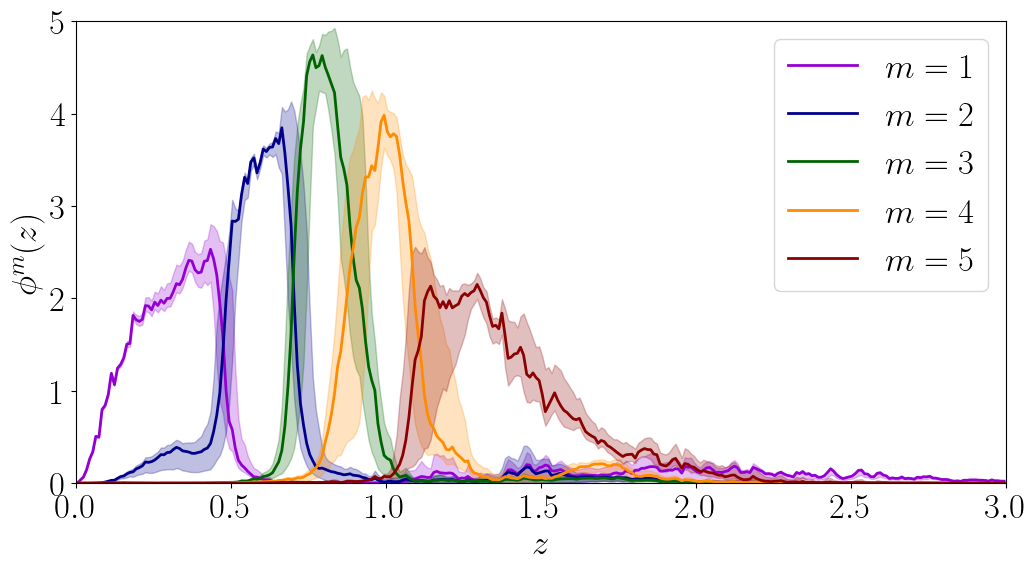

In [8]:
FIGURE, PLOT = pyplot.subplots(nrows = 1, ncols = 1, figsize = (12, 6))

for m in range(BIN_SIZE):
    
    PHI_QUANTILE0 = numpy.quantile(INPUT[:, m, :], q=0.50, axis=0)
    PHI_QUANTILE1 = numpy.quantile(INPUT[:, m, :], q=0.16, axis=0)
    PHI_QUANTILE2 = numpy.quantile(INPUT[:, m, :], q=0.84, axis=0)
    
    PLOT.plot(Z_GRID, PHI_QUANTILE0, color = COLOR[m], linewidth = 2.0, label = r'$m = {:.0f}$'.format(m + 1))

    PLOT.fill_between(Z_GRID, PHI_QUANTILE1, PHI_QUANTILE2, color = COLOR[m], alpha = 0.25)

PLOT.legend()
PLOT.set_xlim(Z1, Z2)
PLOT.set_ylim(PHI1, PHI2)

PLOT.set_xlabel(r'$z$')
PLOT.set_ylabel(r'$\phi^m (z)$')

FIGURE.savefig(PLOT_PATH + 'INPUT_DATA.pdf', bbox_inches = 'tight')

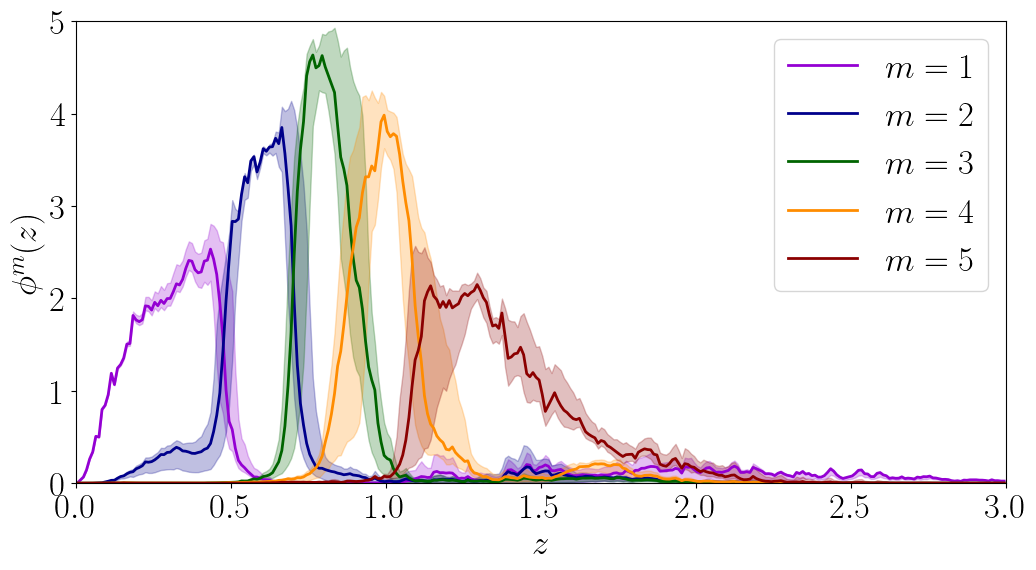

In [9]:
FIGURE, PLOT = pyplot.subplots(nrows = 1, ncols = 1, figsize = (12, 6))

for m in range(BIN_SIZE):
    
    PHI_QUANTILE0 = numpy.quantile(OUTPUT[:, m, :], q=0.50, axis=0)
    PHI_QUANTILE1 = numpy.quantile(OUTPUT[:, m, :], q=0.16, axis=0)
    PHI_QUANTILE2 = numpy.quantile(OUTPUT[:, m, :], q=0.84, axis=0)
    
    PLOT.plot(Z_GRID, PHI_QUANTILE0, color = COLOR[m], linewidth = 2.0, label = r'$m = {:.0f}$'.format(m + 1))

    PLOT.fill_between(Z_GRID, PHI_QUANTILE1, PHI_QUANTILE2, color = COLOR[m], alpha = 0.25)

PLOT.legend()
PLOT.set_xlim(Z1, Z2)
PLOT.set_ylim(PHI1, PHI2)

PLOT.set_xlabel(r'$z$')
PLOT.set_ylabel(r'$\phi^m (z)$')

FIGURE.savefig(PLOT_PATH + 'OUTPUT_DATA.pdf', bbox_inches = 'tight')

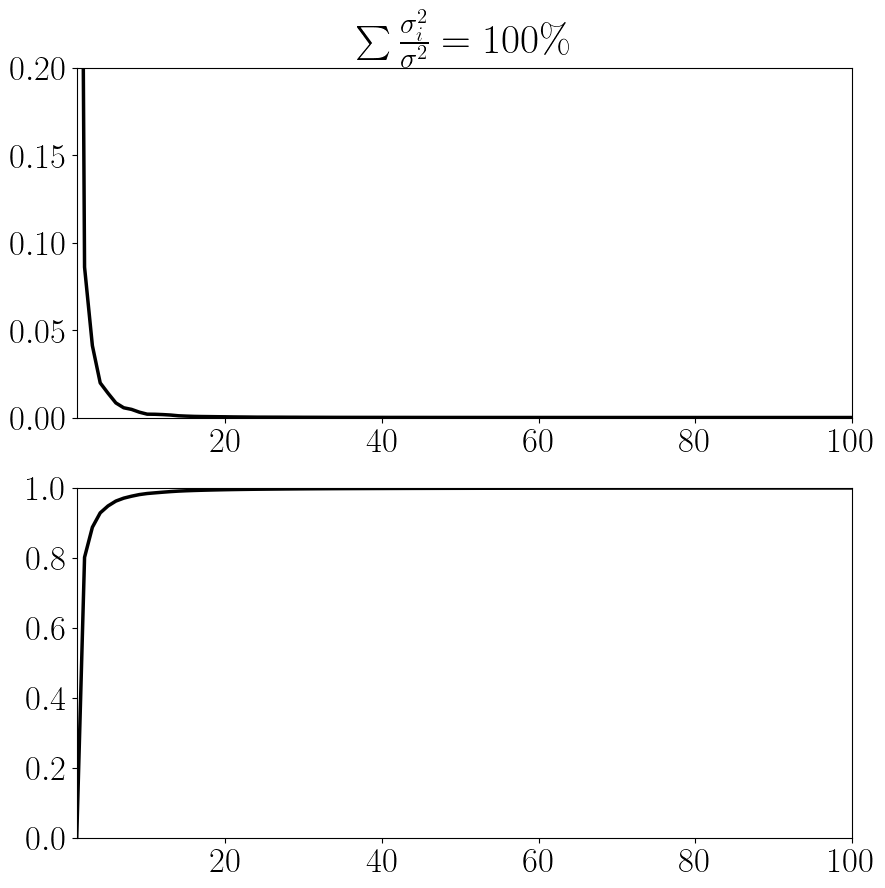

In [10]:
FIGURE, PLOT = pyplot.subplots(nrows = 2, ncols = 1, figsize = (10, 10))

PLOT[0].plot(numpy.arange(1, LATENT_SIZE + 1), MODEL.explained_variance_ratio_, color = 'black', linestyle = '-', linewidth = 2.5)

PLOT[0].set_ylim(0.00, 0.20)
PLOT[0].set_xlim(1, LATENT_SIZE)
PLOT[0].set_title(r'$\sum \frac{\sigma_i^2}{\sigma^2} = ' + '{:.0f}'.format(MODEL.explained_variance_ratio_.sum() * 100) + '\%$')

RATIO = numpy.array([MODEL.explained_variance_ratio_[:n].sum() for n in range(LATENT_SIZE)])

PLOT[1].plot(numpy.arange(1, LATENT_SIZE + 1), RATIO, color = 'black', linestyle = '-', linewidth = 2.5)

PLOT[1].set_ylim(0, 1)
PLOT[1].set_xlim(1, LATENT_SIZE)

FIGURE.savefig(PLOT_PATH + 'VARIANCE.pdf', bbox_inches = 'tight')

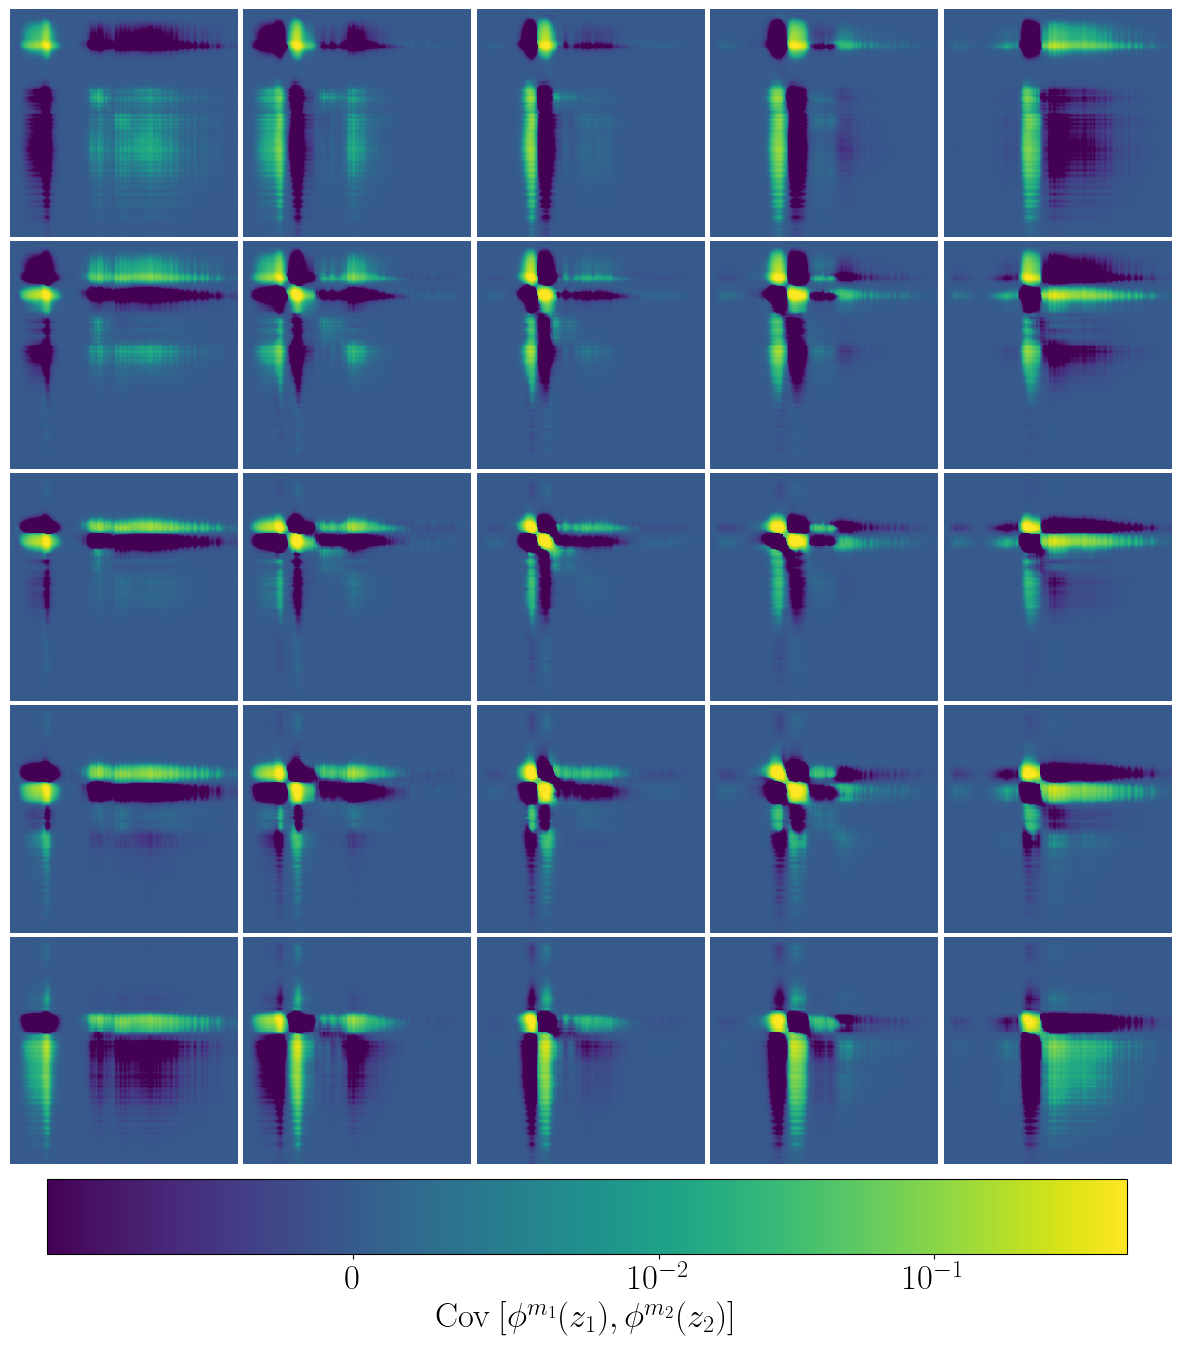

In [11]:
FIGURE, PLOT = pyplot.subplots(nrows = BIN_SIZE, ncols = BIN_SIZE, figsize = (3 * BIN_SIZE, 3 * BIN_SIZE))

INPUT_COVARIANCE = numpy.cov(INPUT_DATA, rowvar = False)

for m in range(BIN_SIZE):

    for n in range(BIN_SIZE):

        NORM = colors.SymLogNorm(vmin = -0.01, vmax = +0.5, linthresh = +0.01)

        MAP = INPUT_COVARIANCE[n * GRID_SIZE: (n + 1) * GRID_SIZE, m * GRID_SIZE: (m + 1) * GRID_SIZE]

        IMAGE = PLOT[n, m].imshow(MAP, norm = NORM, cmap = 'viridis', origin = 'upper')

        PLOT[n, m].axis('off')

CAX = FIGURE.add_axes([0.15, 0.05, 0.72, 0.05])
COLORBAR = FIGURE.colorbar(cax = CAX, mappable = IMAGE, orientation = 'horizontal', label = '$\mathrm{Cov} \: [\phi^{m_1} (z_1), \phi^{m_2} (z_2)]$')

FIGURE.subplots_adjust(wspace = 0.02, hspace = 0.02)
FIGURE.savefig(PLOT_PATH + 'INPUT_COVARIANCE.pdf', bbox_inches = 'tight')

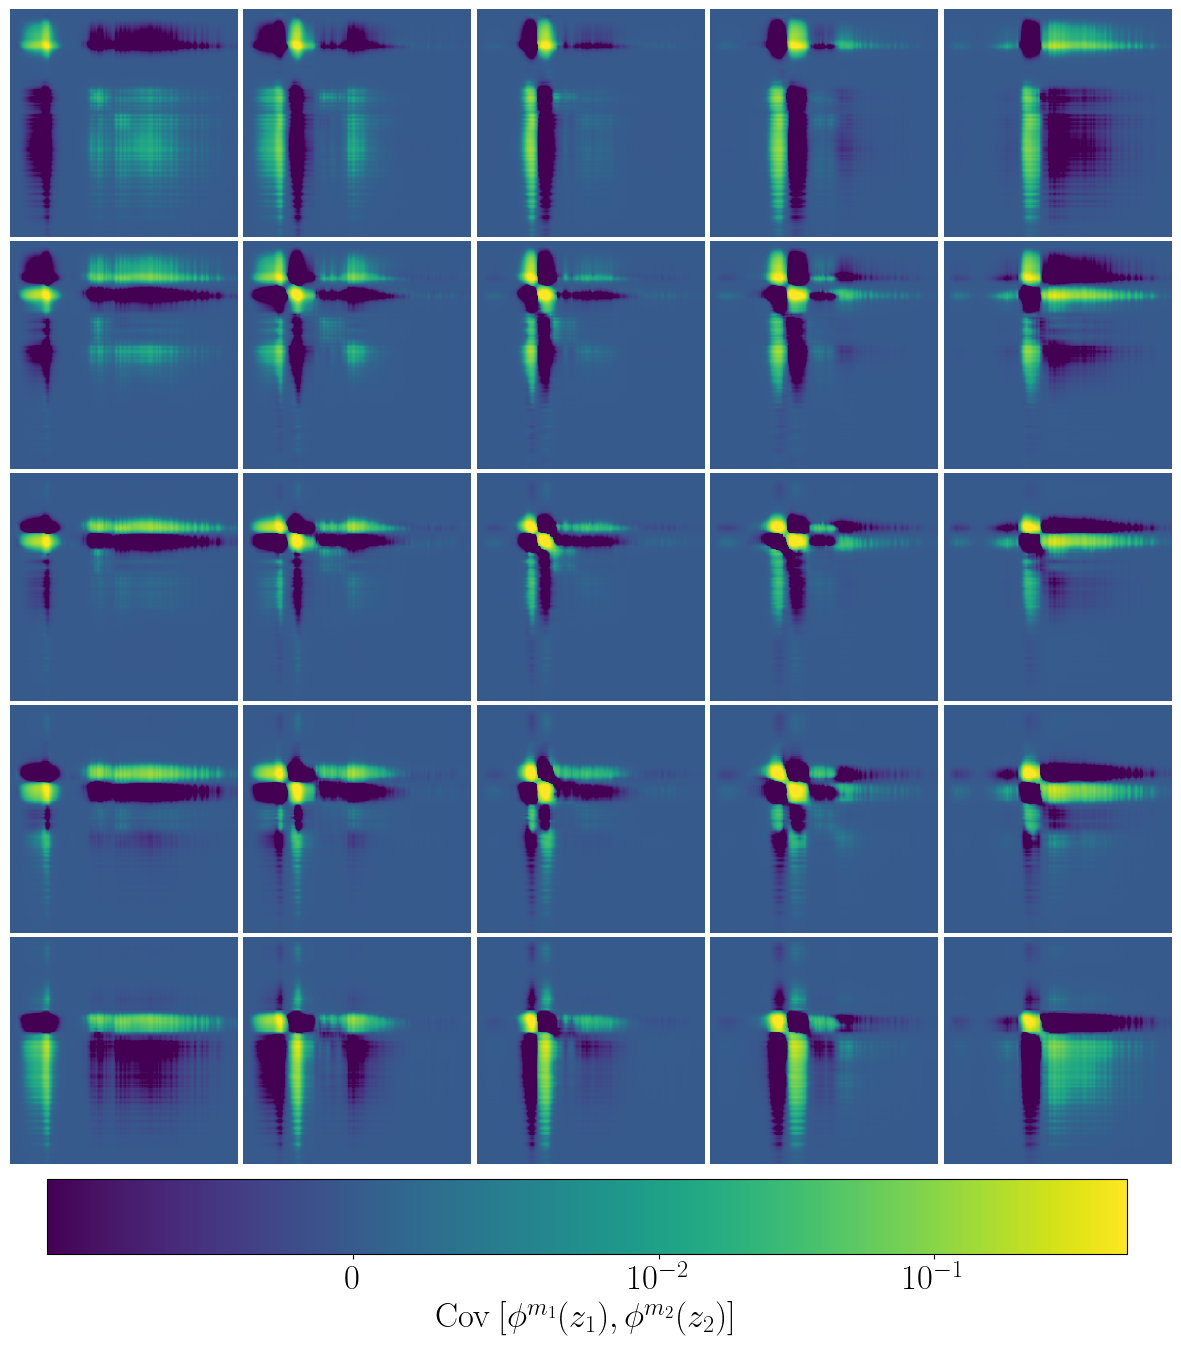

In [12]:
FIGURE, PLOT = pyplot.subplots(nrows = BIN_SIZE, ncols = BIN_SIZE, figsize = (3 * BIN_SIZE, 3 * BIN_SIZE))

OUTPUT_COVARIANCE = numpy.cov(OUTPUT_DATA, rowvar = False)

for m in range(BIN_SIZE):
    
    for n in range(BIN_SIZE):
        
        NORM = colors.SymLogNorm(vmin = -0.01, vmax = +0.5, linthresh = +0.01)
        
        MAP = OUTPUT_COVARIANCE[n * GRID_SIZE: (n + 1) * GRID_SIZE, m * GRID_SIZE: (m + 1) * GRID_SIZE]
        
        IMAGE = PLOT[n, m].imshow(MAP, norm = NORM, cmap = 'viridis', origin = 'upper')
        
        PLOT[n, m].axis('off')
        
CAX = FIGURE.add_axes([0.15, 0.05, 0.72, 0.05])
COLORBAR = FIGURE.colorbar(cax = CAX, mappable = IMAGE, orientation = 'horizontal', label = '$\mathrm{Cov} \: [\phi^{m_1} (z_1), \phi^{m_2} (z_2)]$')

FIGURE.subplots_adjust(wspace = 0.02, hspace = 0.02)
FIGURE.savefig(PLOT_PATH + 'OUTPUT_COVARIANCE.pdf', bbox_inches = 'tight')